# 06 - Formation Water & Environmental Corrections

**Part A - Petrophys Curriculum**

Before we can turn a resistivity log into a water saturation, we need to know two
"invisible" properties of the well: **how salty the formation water is**
(captured by its resistivity `Rw`) and **how hot the rock is** (the temperature
profile). Both are temperature-dependent, and both feed directly into Archie's
equation in lesson 07.

This lesson derives, for well **30_6-5**:
1. the **temperature profile** from a surface temperature and the header's
   bottom-hole temperature (BHT),
2. **mud filtrate resistivity `Rmf`**, cross-checked against the filtrate's
   chloride content and corrected to formation temperature,
3. **formation water resistivity `Rw`** by two independent routes - from salinity,
   and from the SP log - compared with the header value, which is the operator's
   evaluation value,
4. an **invasion characterization** from the deep vs. shallow resistivity curves.

## Learning goals
- Build a **formation temperature profile** with
  `calculate_temperature_profile` from a surface temperature and a BHT, and read
  off the geothermal gradient.
- Correct a resistivity from measured to formation temperature with the **Arps
  relation** (`calculate_rmf`, `correct_rw_temperature`).
- **Cross-check header values** (BHT, `RMF`, `RW`, filtrate chloride) against
  each other before trusting any of them.
- Estimate **`Rw`** two ways - `rw_from_salinity` (and its inverse
  `salinity_from_rw`) and the **SP method** via `RwModule` - and understand when
  each is trustworthy, including how a drifting SP baseline can fake a signal.
- Characterize **invasion** from `RDEP` vs `RSHA`/`RMED` using
  `calculate_invasion_ratio` and `classify_invasion`.
- See exactly **why Rw and temperature are prerequisites** for the saturation
  calculation that follows in lesson 07.

## Why this matters
Archie's equation for water saturation is

$$S_w^{\,n} = \frac{a\,R_w}{\phi^{\,m}\,R_t}$$

Two of those inputs are *environmental*, not measured by a single log:

- **`Rw`** - the resistivity of the formation water. Fresh water is resistive,
  brine is very conductive; get `Rw` wrong and `Sw` is wrong by `Rw^(1/n)` - a
  2x error in `Rw` moves `Sw` by ~41 % for n=2.
- **Temperature** - resistivity of any brine falls as it heats up (ions move more
  freely). Both `Rw` and `Rmf` must be quoted *at formation temperature*, so we
  need the temperature at every depth.

Everything in this lesson exists to pin those two numbers down honestly.


### Prerequisites
This lesson assumes lessons **01-02** (loading a well, curve access). The
saturation math it feeds into is covered in **lesson 07**.

Teaching well: **30_6-5**. It carries `SP`, and the deep/medium/shallow
resistivity triplet `RDEP` / `RMED` / `RSHA` that we need for `Rw`-from-SP and for
invasion analysis. Its LAS `~Params` block also records a few environmental
values: a bottom-hole temperature (`BHT`), a mud-filtrate resistivity (`RMF`), the
filtrate's chloride content (`CLFL`), and a formation-water resistivity (`RW`) with
the temperature it is quoted at (`RWT`). The `RW`/`RWT` pair is the operator's
evaluation value as published in the NPD well data.
The first code cell prints them with their units. Header values are a starting
point, not gospel: this lesson checks each one against the others before using it.

In [1]:
%matplotlib inline
from petrophys.visualization import use_plot_style
use_plot_style()
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import petrophys
from petrophys.io import read_las

print('petrophys', petrophys.__version__)

well = read_las(petrophys.sample('30_6-5'))
print('well       :', well.name)
print('depth      : %.1f - %.1f %s' % (well.start_depth, well.stop_depth, well.depth_unit))
print('has SP / RDEP / RMED / RSHA :',
      well.has_curves(['SP', 'RDEP', 'RMED', 'RSHA']))

# The environmental values in the LAS ~Params block, with their units. Note
# what is missing: no measurement temperature for RMF (RW has RWT), and no TD.
print()
print('LAS ~Params block:')
for p in ['BHT', 'RMF', 'CLFL', 'RW', 'RWT']:
    print('  %-5s = %-8s %s' % (p, well.get_parameter(p), well.get_parameter(p + '__UNIT')))

petrophys 3.0.0


well       : 30/6-5
depth      : 176.6 - 3556.1 m
has SP / RDEP / RMED / RSHA : True

LAS ~Params block:
  BHT   = 126.0    degC
  RMF   = 0.08     ohmm
  CLFL  = 20366.0  mg/l
  RW    = 0.07     ohmm
  RWT   = 230.0    degF


## 1. Temperature profile from surface temp + BHT

Formation temperature is assumed to rise linearly with depth:

`T(depth) = T_surface + gradient * depth`

Given a surface temperature and a bottom-hole temperature (BHT) at total depth,
`calculate_temperature_profile` fits the gradient and evaluates `T` at every log
sample. We take the BHT from the header, which records it in degC, convert it to
degF ourselves and pass it with an explicit unit, so the unit handling is
visible. The header has no TD, so we take the deepest logged sample. For the
surface temperature we use 68 F, the default that `pp.interpret` uses
(`surface_temp_f`), so our profile matches the one the front door builds.

A recorded BHT is usually read before the borehole has recovered from the
cooling effect of mud circulation, so it tends to *understate* the true formation
temperature. Treat the profile as a reasonable, slightly cool estimate.

In [2]:
from petrophys.interpretation.temperature import (
    calculate_temperature_profile,
    calculate_temperature_gradient,
)
from petrophys.interpretation.temperature.temp_gradient import gradient_to_celsius_per_km

# The header BHT is in degC (unit printed above); convert it explicitly.
BHT_C       = float(well.get_parameter('BHT'))
BHT_F       = BHT_C * 9.0 / 5.0 + 32.0
SURFACE_T_F = 68.0          # pp.interpret's default surface temperature
TD          = well.bottom   # no TD in the header -> deepest logged sample (m)

temp_result = calculate_temperature_profile(
    well,
    bht=BHT_F,
    surface_temp=SURFACE_T_F,
    bht_unit='F',
    surface_temp_unit='F',
    td=TD,
    depth_unit='m',
)
temp = temp_result.temperature   # degF, one value per depth sample

print('BHT (header)  : %.0f degC = %.1f F at TD = %.0f m' % (BHT_C, BHT_F, TD))
print('source        :', temp_result.source)
print('surface temp  : %.1f F' % temp_result.surface_temp)
print('gradient      : %.3f F/100ft  (%.1f C/km)'
      % (temp_result.gradient, gradient_to_celsius_per_km(temp_result.gradient)))
print('T range       : %.1f - %.1f F over the logged section'
      % (np.nanmin(temp), np.nanmax(temp)))

# The convenience gradient helper reproduces the same slope from two points:
g = calculate_temperature_gradient(SURFACE_T_F, 0.0, BHT_F, TD,
                                   temp_unit='F', depth_unit='m')
print('cross-check gradient (two-point) : %.3f F/100ft' % g)

BHT (header)  : 126 degC = 258.8 F at TD = 3556 m
source        : linear_gradient_from_BHT
surface temp  : 68.0 F
gradient      : 1.635 F/100ft  (29.8 C/km)
T range       : 77.5 - 258.8 F over the logged section
cross-check gradient (two-point) : 1.635 F/100ft


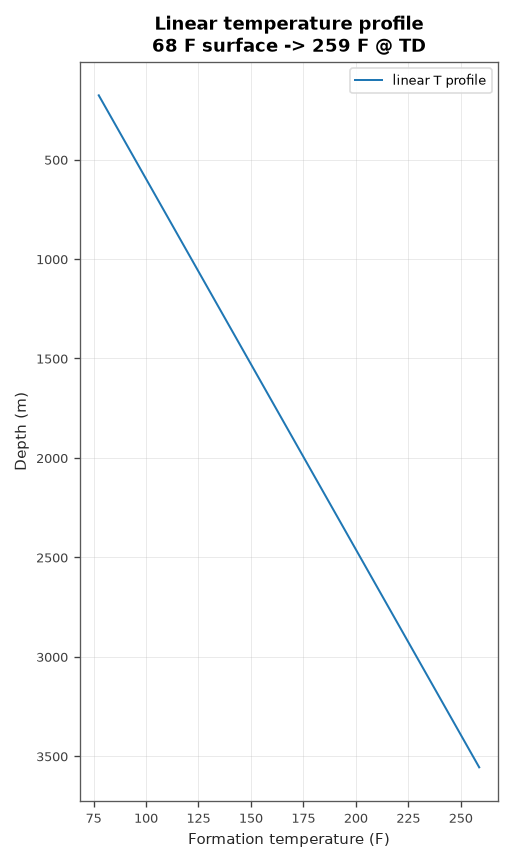

In [3]:
# Temperature-vs-depth profile via the library line-comparison helper
# (x = temperature, series = depth, invert_yaxis so depth increases downward).
from petrophys.visualization import create_line_comparison

fig, ax = create_line_comparison(
    temp, {'linear T profile': well.depth},
    xlabel='Formation temperature (F)', ylabel='Depth (%s)' % well.depth_unit,
    invert_yaxis=True, figsize=(4.5, 8),
    title='Linear temperature profile\n%.0f F surface -> %.0f F @ TD'
          % (SURFACE_T_F, BHT_F))
plt.show()


#### Temperature context

The gradient printed above, close to 30 C/km, is typical of North Sea basins.
The depth-dependent `temp` array is the reference temperature for Rmf and Rw in
the rest of the lesson.

## 2. Mud filtrate resistivity `Rmf` at formation temperature

While drilling, mud filtrate invades the near-wellbore rock. Its resistivity
`Rmf` is measured on a filtrate sample at a stated temperature, and we need it at
*formation* temperature. Resistivity scales with temperature through the
**Arps relation**:

$$R_2 = R_1 \cdot \frac{T_1 + 6.77}{T_2 + 6.77}\quad(T \text{ in }^{\circ}F)$$

The header gives two facts about the filtrate: `RMF`, *without* the temperature
it was measured at, and the filtrate chloride `CLFL`. The chloride is the more
complete fact, because salinity does not depend on temperature. Converting
chloride to an NaCl-equivalent salinity (x 1.65, the NaCl/Cl mass ratio) and then
to resistivity gives `Rmf` at any temperature we choose. Strictly, the NaCl
concentration in mg/l still has to be divided by the brine density to give the
ppm by weight that the salinity-resistivity relation takes; for a filtrate this
dilute the two differ by a few per cent, so the hand calculation below treats
mg/l as ppm. Below we use it to find the temperature at which the header `RMF`
would be consistent, and then move the filtrate to the formation-temperature
profile with `calculate_rmf`.

In [4]:
from petrophys.interpretation.electrical import calculate_rmf
from petrophys.interpretation.electrical.rw.salinity_rw import (
    rw_from_salinity, salinity_from_rw, classify_water_salinity,
)

RMF_HEADER   = float(well.get_parameter('RMF'))    # ohm.m, temperature NOT recorded
CLFL_MG_L    = float(well.get_parameter('CLFL'))   # filtrate chloride, mg/l
FILTRATE_PPM = 1.65 * CLFL_MG_L                    # NaCl equivalent (dilute: mg/l ~ ppm)

RMF_TEMP_F = 75.0                                  # quote the filtrate at 75 F
RMF_75 = float(rw_from_salinity(FILTRATE_PPM, RMF_TEMP_F))

print('filtrate chloride : %.0f mg/l -> ~%.0f ppm NaCl equivalent' % (CLFL_MG_L, FILTRATE_PPM))
print('Rmf from chloride : %.3f ohm.m @ %.0f F' % (RMF_75, RMF_TEMP_F))

# At which temperature does this filtrate read the header value?
t_grid = np.arange(60.0, 300.0, 1.0)
t_match = float(t_grid[np.argmin(np.abs(rw_from_salinity(FILTRATE_PPM, t_grid) - RMF_HEADER))])
print('header RMF %.2f ohm.m fits this filtrate at ~%.0f F' % (RMF_HEADER, t_match))
print('read as a 75 F value, it would imply ~%.0f ppm - far saltier than the chloride'
      % salinity_from_rw(RMF_HEADER, RMF_TEMP_F))

# Carry the chloride-derived Rmf forward and move it to formation temperature.
rmf = calculate_rmf(
    rmf_surface=RMF_75,
    temp_measured=RMF_TEMP_F,
    temp_formation=temp,      # array -> Rmf becomes depth-varying
)
print()
print('Rmf @ formation T : %.3f - %.3f ohm.m (shallow -> deep)'
      % (np.nanmax(rmf), np.nanmin(rmf)))
print('-> Rmf drops with depth because the rock gets hotter and brine conducts')
print('   more easily. Always correct resistivities to formation T before use.')

filtrate chloride : 20366 mg/l -> ~33604 ppm NaCl equivalent
Rmf from chloride : 0.186 ohm.m @ 75 F
header RMF 0.08 ohm.m fits this filtrate at ~183 F
read as a 75 F value, it would imply ~90023 ppm - far saltier than the chloride

Rmf @ formation T : 0.180 - 0.057 ohm.m (shallow -> deep)
-> Rmf drops with depth because the rock gets hotter and brine conducts
   more easily. Always correct resistivities to formation T before use.


#### Which Rmf to trust

The chloride is a measured salinity, so it describes the filtrate
unambiguously. The header `RMF` agrees with it only if it was measured hot, at
the temperature printed above - far above the 75 F a surface measurement is
normally quoted at. So we carry the chloride-derived value forward. Note how
salty this filtrate is: about as salty as sea water, which is typical of an
offshore water-based mud. That matters for the SP section below.

`pp.interpret` treats this header differently unless you tell it otherwise: it
takes `RMF` and, because no temperature is recorded (no `RMFT`, and no `MFST`
mud-filtrate sample temperature), assumes it was measured at 75 F. To use the
chloride-derived value instead, pass `rmf_at_meas_temp` and `rmf_meas_temp_f`.
Section 5 shows the call.

The workflow makes the chloride conversion itself when the filtrate chloride is
its Rmf source: a header `CLFL`, or the setting `rmf_chlorides_mg_l`, is read as
chlorides in mg/l (the mud-report unit), multiplied by 58.44/35.45 and divided by
the brine density (McCain, 1991) to give NaCl ppm by weight, which then gives
Rmf. That route comes after a supplied or header Rmf and a stated
`rmf_salinity_ppm`, and before a mud resistivity Rm, so on this well the header
`RMF` wins. `chlorides_to_nacl_ppm` in
`petrophys.interpretation.electrical.rw.salinity_rw` is the same conversion.

## 3. Formation water resistivity `Rw`

`Rw` is the star input. We derive it two independent ways.

### 3a. From salinity (if you know / assume the water salinity)
`rw_from_salinity` uses the Schlumberger empirical NaCl relation, corrected to
temperature with Arps. Its inverse, `salinity_from_rw`, lets you sanity-check any
`Rw` you obtain by another method by converting it back to an equivalent salinity.


In [5]:
from petrophys.interpretation.electrical.rw.salinity_rw import (
    rw_from_salinity, salinity_from_rw, classify_water_salinity,
)

# Formation temperature at a mid-reservoir depth, say 2900 m:
z_ref = 2900.0
i_ref = int(np.nanargmin(np.abs(well.depth - z_ref)))
T_ref = float(temp[i_ref])
print('reference depth %.0f m -> T = %.1f F' % (z_ref, T_ref))

print()
print('%-12s %-10s %-12s' % ('salinity(ppm)', 'Rw(ohm.m)', 'class'))
for sal in [10000, 35000, 70000, 150000]:
    rw = float(rw_from_salinity(sal, T_ref))
    print('%-12d %-10.4f %-12s' % (sal, rw, classify_water_salinity(sal)))

# Pick a North Sea-like formation-brine salinity and take its Rw as our estimate:
SALINITY_PPM = 35000.0
rw_from_sal = float(rw_from_salinity(SALINITY_PPM, T_ref))
print()
print('assumed salinity %.0f ppm -> Rw = %.4f ohm.m @ %.0f F'
      % (SALINITY_PPM, rw_from_sal, T_ref))
print('inverse check: salinity_from_rw(%.4f) = %.0f ppm'
      % (rw_from_sal, salinity_from_rw(rw_from_sal, T_ref)))

reference depth 2900 m -> T = 223.6 F

salinity(ppm) Rw(ohm.m)  class       
10000        0.2003     saline      
35000        0.0636     saline      
70000        0.0349     saline      
150000       0.0191     brine       

assumed salinity 35000 ppm -> Rw = 0.0636 ohm.m @ 224 F
inverse check: salinity_from_rw(0.0636) = 35000 ppm


### 3b. From the SP log - and how baseline drift can fool it

Where a saline formation sits opposite a fresher mud filtrate, the SP deflects.
The static SP (SSP) relates `Rmf` and `Rw`:

`SSP = -K * log10(Rmf / Rw)`, with `K = 61 + 0.133 * T` (T in degF)

`sp_rw_in_window` (in `petrophys.interpretation.electrical.rw`) automates the
hard part: it cuts the depth window we choose, moves `Rmf` from its measurement
temperature to formation temperature, lets `RwModule` pick a clean-sand and a
shale SP baseline inside the window, takes their difference as the SSP, and
inverts for `Rw`. We run it twice: once on the **whole log** (about 3,400 m of
section), and once on a **local window**, 2800-2958 m: the Brent Group sands plus the
Heather shale just above them. Predict the answer
first. The filtrate (section 2) and the brine assumed in section 3a have similar
salinities, so `Rmf/Rw` is close to 1 and a genuine SSP should be only a few mV.

One bookkeeping subtlety: the SP method returns the **median** `Rw` over the
depths it used, so that number is quoted at the **median temperature of those
depths** (`window_temp_f` in the result), *not* at our 2900 m reference
temperature. `sp_rw_in_window` Arps-shifts it to the `reference_temp_f` we pass,
`T_ref`, so the two answers can be compared. Comparing resistivities quoted at
different temperatures is exactly the mistake this lesson exists to prevent.

In [6]:
from petrophys.interpretation.electrical.rw import correct_rw_temperature, sp_rw_in_window

# (1) Baselines picked over the whole log
whole = sp_rw_in_window(well, rmf=RMF_75, rmf_temp_f=RMF_TEMP_F, temperature_f=temp,
                        reference_temp_f=T_ref)

# (2) Baselines picked locally: the Brent Group sands and the Heather shale above them
LO, HI = 2800.0, 2958.0
local = sp_rw_in_window(well, rmf=RMF_75, rmf_temp_f=RMF_TEMP_F, temperature_f=temp,
                        top=LO, bottom=HI, reference_temp_f=T_ref)
rw_sp_whole, rw_sp_local = whole.rw, local.rw      # both at T_ref

# The SSP the two salinities predict at T_ref
rmf_tref = float(rw_from_salinity(FILTRATE_PPM, T_ref))
K_ref = 61.0 + 0.133 * T_ref
print('expected SSP (filtrate vs %.0f ppm brine at %.0f F): %.1f mV'
      % (SALINITY_PPM, T_ref, -K_ref * np.log10(rmf_tref / rw_from_sal)))
print()
print('%-18s %9s %9s %7s %12s %12s' % ('SP baselines', 'clean mV', 'shale mV',
                                      'SSP mV', 'Rw @ T_ref', 'salinity'))
for label, res in [('whole log', whole), ('%.0f-%.0f m' % (LO, HI), local)]:
    print('%-18s %9.1f %9.1f %7.1f %12.4f %8.0f ppm'
          % (label, res.sp_clean_mv, res.sp_shale_mv, res.ssp_mv,
             res.rw, salinity_from_rw(res.rw, T_ref)))

expected SSP (filtrate vs 35000 ppm brine at 224 F): -1.4 mV

SP baselines        clean mV  shale mV  SSP mV   Rw @ T_ref     salinity
whole log               32.3      77.5   -45.2       0.0189   152194 ppm
2800-2958 m             59.4      64.5    -5.2       0.0579    38945 ppm


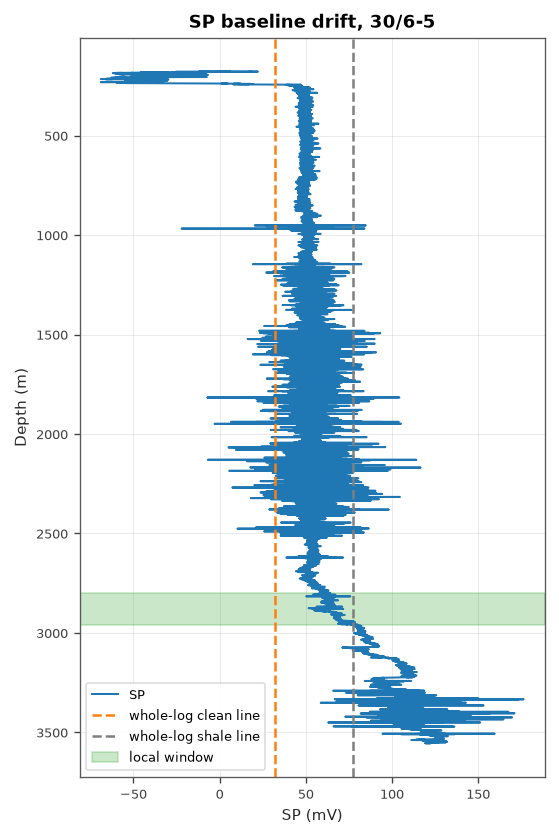

In [7]:
# Where did the whole-log "SSP" come from? Plot the SP against depth with the
# two whole-log baselines and the local window.
from petrophys.visualization import create_line_comparison

fig, ax = create_line_comparison(
    well.get('SP').data, {'SP': well.depth},
    xlabel='SP (mV)', ylabel='Depth (%s)' % well.depth_unit,
    invert_yaxis=True, figsize=(5, 8),
    title='SP baseline drift, 30/6-5')
ax.axvline(whole.sp_clean_mv, color='tab:orange', ls='--',
           label='whole-log clean line')
ax.axvline(whole.sp_shale_mv, color='tab:gray', ls='--',
           label='whole-log shale line')
ax.axhspan(LO, HI, color='tab:green', alpha=0.25, label='local window')
ax.legend(fontsize=8, loc='lower left')
plt.show()

#### Reading the two SP answers

The SP baseline is not constant: it drifts by tens of mV between the shallow
section and the deepest sands. The whole-log pick takes its clean line from the
shallower section and its shale line from the deeper shales, so the "SSP" it
measures is mostly that drift. The `Rw` it returns implies a brine several times
saltier than the filtrate, the salinity estimate or the operator's value
suggest (section 3c).

The local pick compares sand with the shale right next to it. It finds the
small deflection the salinities predict and returns an `Rw` close to the
filtrate's resistivity. A small SSP means exactly that: the formation water is
about as salty as the filtrate.

Two caveats remain. With an SSP of only a few mV, a few mV of baseline noise is a
large relative error, so treat the local SP answer as a consistency check rather
than a measurement. And hydrocarbons suppress the SP deflection, so in the
oil-bearing Brent Group sands it may understate the true contrast.

### 3c. Reconcile the estimates

Now put every `Rw` on one table, quoted at the same temperature `T_ref`,
together with its equivalent salinity: the salinity route, both SP picks, and
the header `RW`. The header value is the operator's evaluation value, 0.070 ohm.m
at `RWT` = 230 F (NPD well data; lesson 09 compares our net pay with that
evaluation), so we Arps-shift it from 230 F to `T_ref` like every other entry.
Independent routes that agree build confidence. A value that disagrees by a
large factor points to a broken assumption.

In [8]:
RW_OPERATOR, RW_OPERATOR_T = 0.070, 230.0     # ohm.m at 230 F (operator's evaluation)
rw_operator_tref = float(correct_rw_temperature(RW_OPERATOR, from_temp=RW_OPERATOR_T,
                                                to_temp=T_ref))
RW_HEADER = float(well.get_parameter('RW'))    # ohm.m, quoted at RWT
RWT_HEADER = float(well.get_parameter('RWT'))  # degF
assert (RW_HEADER, RWT_HEADER) == (RW_OPERATOR, RW_OPERATOR_T)   # same source

rows = [
    ('salinity, %.0f ppm assumed' % SALINITY_PPM, rw_from_sal),
    ('SP, whole-log baselines', rw_sp_whole),
    ('SP, local baselines', rw_sp_local),
    ('header RW, %.3f @ %.0f F' % (RW_HEADER, RWT_HEADER), rw_operator_tref),
]
compare = pd.DataFrame({
    'estimate': [label for label, _ in rows],
    'Rw @ T_ref (ohm.m)': [round(value, 4) for _, value in rows],
    'equiv. salinity (ppm)': [int(round(float(salinity_from_rw(value, T_ref)), -2))
                              for _, value in rows],
})
print('T_ref = %.0f F (at %.0f m)' % (T_ref, z_ref))
print(compare.to_string(index=False))

consistent = [rw_from_sal, rw_sp_local, rw_operator_tref]
spread = max(consistent) / min(consistent)
print()
print('spread of salinity / local SP / header : %.2fx  (Sw impact for n=2: ~%.0f %%)'
      % (spread, 100 * (np.sqrt(spread) - 1.0)))
print('header Rw / whole-log SP Rw            : %.1fx' % (rw_operator_tref / rw_sp_whole))
print('header RW if its RWT were ignored (0.070 taken at T_ref): Sw changes by ~%.0f %%'
      % (100 * (np.sqrt(RW_HEADER / rw_operator_tref) - 1.0)))

T_ref = 224 F (at 2900 m)
                   estimate  Rw @ T_ref (ohm.m)  equiv. salinity (ppm)
salinity, 35000 ppm assumed              0.0636                  35000
    SP, whole-log baselines              0.0189                 152200
        SP, local baselines              0.0579                  38900
   header RW, 0.070 @ 230 F              0.0719                  30500

spread of salinity / local SP / header : 1.24x  (Sw impact for n=2: ~12 %)
header Rw / whole-log SP Rw            : 3.8x
header RW if its RWT were ignored (0.070 taken at T_ref): Sw changes by ~-1 %


#### What the table says

Three independent routes - an assumed North Sea salinity, the local SP pick and
the header (operator) value - agree within the spread printed above. That is
comfortably small for saturation work: `Sw` scales with `Rw^(1/n)`, so a 2x
`Rw` error moves `Sw` by ~41 % for n=2, and estimates within ~25-30 % of each
other are comfortable. One value does not fit: the **whole-log SP** answer, an
artefact of baseline drift (section 3b).

The header `RW` is only usable because it comes with `RWT`. Here 230 F is close
to the reservoir temperature, so ignoring it would cost little (last line
above), but a header `RW` quoted at a surface temperature such as 68-75 F is
several times higher than the in-situ value and must be Arps-corrected before
use. Lesson 07 meets exactly that case in the carbonate well HW-3.

The following lessons therefore use **`Rw = 0.070` ohm.m at 230 F**. `pp.interpret`
reads `RW` together with `RWT` from this header and corrects it itself. For a well
whose header lacks the temperature, pass the value *with its temperature*:
`pp.interpret(well, rw=0.07, rw_meas_temp_f=230)`. Without `rw_meas_temp_f` the
library takes the value as Rw at the well's median formation temperature, and
warns that it did; for a value measured at another temperature that changes
`Sw` strongly.

## 4. Invasion characterization (RDEP vs RSHA / RMED)

Resistivity tools read at different depths of investigation. Comparing a **deep**
curve (`RDEP`, reads the true, uninvaded formation `Rt`) with a **shallow** curve
(`RSHA`), used as a proxy for the flushed-zone `Rxo`, tells us about invasion and, indirectly,
about movable hydrocarbons.

The **invasion ratio** is `Rxo / Rt`:

- **ratio < 0.8 - conductive invasion:** the flushed zone is more conductive than
  the uninvaded rock; with a filtrate about as salty as the formation water, as
  here, that usually means filtrate has displaced hydrocarbon.
- **0.8 <= ratio <= 1.2 - minimal invasion:** little contrast (`Rmf` ~ `Rw` in
  water-bearing rock).
- **ratio > 1.2 - resistive invasion:** the flushed zone is more resistive,
  typically a fresher filtrate invading saline formation water.

Invasion needs permeability, so these classes only mean invasion in permeable
rock. We compute the ratio over the whole well and then over the Brent Group sands
alone. The display window, 2350-2950 m, runs from the overlying shales down
through the Brent Group (2841-2958 m). The separation between the deep and
shallow curves is shaded on the resistivity track itself, as industry composites
do (gold = shallow above deep, green = shallow below deep).

In [9]:
from petrophys.interpretation.electrical import calculate_invasion_ratio, classify_invasion

rsha = well.get('RSHA').data   # shallow  -> Rxo (flushed zone)
rmed = well.get('RMED').data   # medium
rdep = well.get('RDEP').data   # deep     -> Rt  (true formation)

ratio = calculate_invasion_ratio(rsha, rdep)   # Rxo / Rt, invalid samples -> NaN
finite = np.isfinite(ratio)
print('invasion ratio: %d valid / %d samples' % (int(finite.sum()), len(ratio)))
print('median ratio  : %.2f' % np.nanmedian(ratio))

def regime_shares(mask):
    """Print the percentage of the masked samples in each invasion regime."""
    values = np.array([c.value for c in classify_invasion(ratio[mask])])
    for label in ['conductive', 'minimal', 'resistive']:
        print('  %-11s : %5.1f %%' % (label, 100.0 * np.mean(values == label)))

print('Whole well (shales included):')
regime_shares(finite)

# Invasion needs permeability: repeat for the Brent Group sands only (GR below
# 60 gAPI), split at 2900 m where the deep resistivity drops.
gr_log = well.get('GR').data
sand = finite & (gr_log < 60.0)
brent_sand = sand & (well.depth >= 2841.0) & (well.depth <= 2958.0)
for top, base in [(2841.0, 2900.0), (2900.0, 2958.0)]:
    m = sand & (well.depth >= top) & (well.depth < base)
    print('Brent Group sands %.0f-%.0f m (%d samples, median RDEP %.1f ohm.m):'
          % (top, base, int(m.sum()), np.nanmedian(rdep[m])))
    regime_shares(m)

invasion ratio: 22079 valid / 22176 samples
median ratio  : 1.19
Whole well (shales included):
  conductive  :  18.4 %
  minimal     :  32.3 %
  resistive   :  49.2 %
Brent Group sands 2841-2900 m (225 samples, median RDEP 14.8 ohm.m):
  conductive  :  77.8 %
  minimal     :  14.2 %
  resistive   :   8.0 %
Brent Group sands 2900-2958 m (229 samples, median RDEP 2.1 ohm.m):
  conductive  :   3.5 %
  minimal     :  28.8 %
  resistive   :  67.7 %


In [10]:
from petrophys.interpretation.electrical.invasion import InvasionModule

# The high-level module does the same and returns tidy statistics, and it will
# fall back to RMED as a shallow proxy where RSHA is missing.
inv = InvasionModule(rxo_curve='RSHA', rt_curve='RDEP')
inv_result = inv.analyze(well)
s = inv_result.statistics
print('curves used   : Rxo=%s  Rt=%s' % (s['rxo_curve'], s['rt_curve']))
print('mean ratio    : %.2f   median : %.2f' % (s['mean_ratio'], s['median_ratio']))
print('conductive    : %.1f %%' % s['conductive_percent'])
print('minimal       : %.1f %%' % s['minimal_percent'])
print('resistive     : %.1f %%' % s['resistive_percent'])

curves used   : Rxo=RSHA+RMED  Rt=RDEP
mean ratio    : 1.35   median : 1.19
conductive    : 18.4 %
minimal       : 32.6 %
resistive     : 49.0 %


[repository]\src\petrophys\preprocessing\standardization\curve_standardizer.py:834: UserWarning: SWC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units.
  standardize_core_saturation(new_curve, inplace=True)
[repository]\src\petrophys\preprocessing\standardization\curve_standardizer.py:834: UserWarning: SOC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units.
  standardize_core_saturation(new_curve, inplace=True)


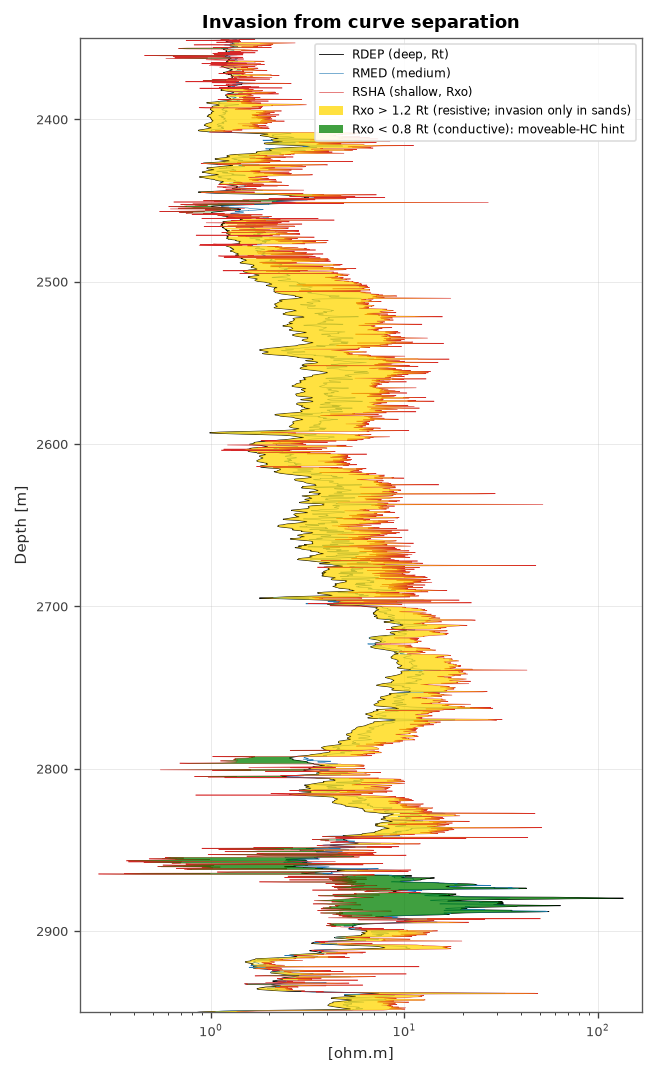

In [11]:
# The industry display for invasion: the resistivity triplet with the
# deep-vs-shallow SEPARATION shaded and labeled. The Rxo/Rt ratio itself is a
# computed diagnostic (it drives the classification statistics above); it is
# not shown as a track because composites do not carry one - interpreters read
# the shaded separation directly.
from petrophys.visualization import LogPlot
from matplotlib.patches import Patch

lp = LogPlot(well, figsize=(5.5, 9))
lp.create_figure(n_tracks=1)

lp.add_curve(0, 'RDEP', color='black',    linewidth=0.5, log_scale=True,
             label='RDEP (deep, Rt)')
lp.add_curve(0, 'RMED', color='tab:blue', linewidth=0.35, log_scale=True,
             label='RMED (medium)')
lp.add_curve(0, 'RSHA', color='tab:red',  linewidth=0.35, log_scale=True,
             label='RSHA (shallow, Rxo)')

# Shade only MEANINGFUL separation (the same 0.8x / 1.2x bands the numeric
# classification uses) so the profile reads as bands, not noise.
_d  = well.depth
_rd = well.get('RDEP').data
_rs = well.get('RSHA').data
_ok = np.isfinite(_rd) & np.isfinite(_rs)
lp.axes[0].fill_betweenx(_d, _rs, _rd, where=_ok & (_rs < 0.8 * _rd),
                         color='green', alpha=0.75, linewidth=0, zorder=3)
lp.axes[0].fill_betweenx(_d, _rs, _rd, where=_ok & (_rs > 1.2 * _rd),
                         color='gold', alpha=0.75, linewidth=0, zorder=3)

# Label the fills so the figure explains itself.
handles, labels = lp.axes[0].get_legend_handles_labels()
handles += [Patch(facecolor='gold', alpha=0.75),
            Patch(facecolor='green', alpha=0.75)]
labels  += ['Rxo > 1.2 Rt (resistive; invasion only in sands)',
            'Rxo < 0.8 Rt (conductive): moveable-HC hint']
lp.axes[0].legend(handles, labels, loc='upper right', fontsize=7)

lp.axes[0].set_title('Invasion from curve separation')
# From the overlying shales down through the Brent Group (2841-2958 m).
lp.set_depth_range(2350.0, 2950.0)
lp.show()

#### Reading the invasion track

Read the separation only where the rock can take filtrate. Above the reservoir,
through the Viking Group shales (about 2450-2841 m), the shallow curve reads
above the deep curve over long stretches (gold). Shale is effectively
impermeable, so that separation is not invasion: it reflects how differently
the tools respond to shale and to the borehole. It is also why the whole-well
statistics above, which include every shale, must not be read as "half the well
is invaded".

In the Brent Group sands the separation follows the fluids (compare the two sands-only
blocks above):

- **Above about 2900 m**, where the deep resistivity is high, most sand samples
  are conductive (green): the flushed zone is more conductive than the
  uninvaded rock. Because the filtrate is about as salty as the formation water,
  the likely cause is filtrate displacing hydrocarbon near the wellbore -
  evidence that the hydrocarbon there is moveable.
- **Below about 2900 m**, where the deep resistivity falls to a few ohm.m, the
  sands show mild resistive separation. That is what water-bearing sand shows
  when the filtrate is slightly fresher than the formation water - consistent
  with the small SSP of the local SP pick.

## 5. How this feeds the saturation calculation

Pulling it together, lesson 07's Archie/Simandoux call will need:

| input | where it came from here |
|---|---|
| **`Rw`** | the header (operator) 0.070 ohm.m at 230 F, cross-checked against a salinity estimate and a local SP pick at one reference temperature |
| **formation temperature** | linear profile from the header BHT -> `temp` array |
| **`Rmf`** | filtrate chloride (`CLFL`) -> 75 F value -> Arps-corrected to formation T (lesson 07 simplifies this to the header 0.08 ohm.m, close to the 0.066 ohm.m the chloride gives at reservoir temperature) |
| **`Rt`** | deep resistivity `RDEP` |
| invasion context | `Rxo/Rt` ratio in the sands, to know where filtrate matters |

Without a temperature-consistent `Rw`, the saturation numbers are meaningless -
that is why this environmental step comes *before* saturation, not after.

The front door takes the same inputs. `pp.interpret` builds the temperature
profile from the header BHT itself; we pass `Rw` and `Rmf` *with their
measurement temperatures*, so nothing is assumed. The cell below runs the full
interpretation and prints only the environmental steps from its trace.

The run also prints `UserWarning`s about the core saturation curves `SWC` and
`SOC`: this LAS labels them as fractions (`frac`) but stores them in percent, so
the library divides them by 100 when it reads the core data and tells you it did.
They do not affect the steps shown here.

In [12]:
import petrophys as pp

result = pp.interpret(well,
                      rw=RW_OPERATOR, rw_meas_temp_f=RW_OPERATOR_T,
                      rmf_at_meas_temp=RMF_75, rmf_meas_temp_f=RMF_TEMP_F)
trace = result.to_dataframe().set_index('Step')
for step in ['temperature', 'rmf']:
    print('%-12s: %s' % (step, trace.loc[step, 'Decisions']))

[repository]\src\petrophys\preprocessing\standardization\curve_standardizer.py:834: UserWarning: SWC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units.
  standardize_core_saturation(new_curve, inplace=True)
[repository]\src\petrophys\preprocessing\standardization\curve_standardizer.py:834: UserWarning: SOC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units.
  standardize_core_saturation(new_curve, inplace=True)


temperature : Temperature profile anchored to BHT metadata/input | Gradient = 1.6354 F/100ft (29.81 C/km) | Temp range: 77.5 - 258.8 F
rmf         : Rmf corrected from 0.186 ohm.m @ 75F across the temperature profile


In [13]:
summary = pd.DataFrame({
    'quantity': ['surface temperature', 'BHT (header, at TD)', 'geothermal gradient',
                 'reference temperature (%.0f m)' % z_ref,
                 'Rmf from filtrate chloride', 'Rmf @ reference T',
                 'Rw, operator (at reference T)',
                 'Rw, %.0fk ppm salinity (at reference T)' % (SALINITY_PPM / 1000),
                 'Rw, local SP pick (at reference T)',
                 'median invasion ratio, Brent Group sands'],
    'value': ['%.0f F' % SURFACE_T_F, '%.0f degC = %.1f F' % (BHT_C, BHT_F),
              '%.2f F/100ft' % temp_result.gradient, '%.0f F' % T_ref,
              '%.3f ohm.m @ %.0f F' % (RMF_75, RMF_TEMP_F), '%.4f ohm.m' % rmf_tref,
              '%.4f ohm.m' % rw_operator_tref, '%.4f ohm.m' % rw_from_sal,
              '%.4f ohm.m' % rw_sp_local, '%.2f' % np.nanmedian(ratio[brent_sand])],
})
print(summary.to_string(index=False))

                                quantity              value
                     surface temperature               68 F
                     BHT (header, at TD) 126 degC = 258.8 F
                     geothermal gradient       1.64 F/100ft
          reference temperature (2900 m)              224 F
              Rmf from filtrate chloride 0.186 ohm.m @ 75 F
                       Rmf @ reference T       0.0659 ohm.m
           Rw, operator (at reference T)       0.0719 ohm.m
   Rw, 35k ppm salinity (at reference T)       0.0636 ohm.m
      Rw, local SP pick (at reference T)       0.0579 ohm.m
median invasion ratio, Brent Group sands               1.02


## Pitfalls & parameter choices
- **Temperature drives resistivity.** Every `Rw`/`Rmf` must be quoted at formation
  temperature. A wrong gradient shifts `Rw` and hence `Sw` systematically, and a
  recorded BHT usually reads a little low.
- **A resistivity without its temperature is half a fact.** This header gives
  `RMF` with no measurement temperature (`RW` comes with `RWT`). Cross-check against
  anything temperature-independent (the filtrate chloride, a water analysis) before use.
- **Header values must agree with each other.** The header `RMF` matches its own
  filtrate chloride only if it was measured at about 183 F, far above a normal
  surface measurement. Check that header values are consistent with each other and
  with physics before trusting any of them.
- **The SP method needs a salinity contrast and a stable baseline.** It fails in
  shale, when filtrate and formation water are similarly salty (as here), with
  KCl or oil-based mud, and when the baseline drifts. Pick the clean and shale
  lines locally, and check the SSP magnitude: a few mV of deflection cannot
  support a precise `Rw`.
- **Salinity is often a guess.** If you have a produced-water analysis or an
  offset well `Rw`, prefer it. `salinity_from_rw` is handy to translate any `Rw`
  back into an intuitive salinity for a gut check.
- **Invasion needs true shallow/deep curves and permeable rock.** With only
  `RMED` as a proxy the contrast is muted (the module flags when it falls back
  to a medium proxy), and separation in shale is not invasion.
- **OBM has no `Rmf`.** Oil-based mud does not conduct; the SP/`Rmf` workflow does
  not apply and you fall back to a known or offset `Rw`. With `mud_type='OBM'`,
  `pp.interpret` takes Rw from `rw=`, a header `RW` or a stated salinity, never
  from the SP or `Rxo/Rt`; without any of those it falls back to the apparent Rw
  of the clean, porous samples (P5 of `Rt * PHIE^m / a`), with a warning. It
  computes no `Sxo` or moveable-hydrocarbon index for oil-based mud.

## Recap
- A **linear temperature profile** from surface T + the header BHT gives formation
  temperature at every depth - the backbone for all resistivity corrections.
- **Arps** rescales resistivity between temperatures; `calculate_rmf` uses it to
  put `Rmf` on a formation-temperature footing, and `correct_rw_temperature`
  moves every `Rw` estimate onto the same basis before any comparison.
- **Header values need cross-checking:** the filtrate chloride pins `Rmf`, and the
  header `RW` (0.070 ohm.m at `RWT` 230 F) agrees with the salinity and local SP
  estimates once all are quoted at one temperature.
- **`Rw`** can be had from **salinity** or from the **SP log**; quoted at the
  same temperature, agreement between them (and with the operator's value) is
  your confidence check. A whole-log SP pick can be dominated by baseline drift;
  pick SP baselines locally.
- The **invasion ratio** `Rxo/Rt` from `RDEP` vs `RSHA` classifies each depth as
  conductive / minimal / resistive invasion; in permeable sands a conductive
  flushed zone flags moveable hydrocarbon.
- All of this exists to hand a temperature-consistent **`Rw`** (and `Rt`, `T`) to
  the **saturation** calculation in lesson 07.

## Try it yourself
> **Exercise 1.** Rerun the temperature profile with a hotter BHT (e.g. 300 F,
> allowing for a BHT that has not recovered from circulation). How much do
> `T_ref`, the filtrate `Rmf` at `T_ref` and the salinity-derived `Rw` move?
>
> **Exercise 2.** Sweep assumed salinity from 20k to 120k ppm and plot
> `rw_from_salinity` vs salinity at `T_ref`. Where does it cross the operator's
> `Rw` shifted to `T_ref`? That crossing is the salinity the operator's value implies.
>
> **Exercise 3.** Move the local SP window: try 2593-2958 m (all of the Heather
> shale plus the Brent Group), then 3071-3223 m (around the Cook sand). How stable is the
> SP-derived `Rw` at `T_ref`?
>
> **Exercise 4.** Use `InvasionModule.add_to_well(well)` to attach an `INV_RATIO`
> curve, then colour the resistivity track by invasion class. Do the conductive
> streaks line up with the low-GR Brent Group sands?

## What's next
Part A continues. In **07 - Water Saturation** we combine everything - clay
volume, porosity, the mineral model, and the `Rw`/temperature derived here - to
compute **water saturation**; **08 - Permeability** and **09 - Reservoir Quality
& Net Pay** then finish Part A.
